# TRAM Multi-Label Classification: SecBERT vs RoBERTa (Consolidated)

## Cell 1 — Configuration and Flags
Set up pathways, global model definitions, evaluation parameters, and optional optimization flags (all defaulted to False to guarantee identical reproduction of results).

In [ ]:
import os

# Optional Google Drive Mount
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

DATA_DIR = "/content/drive/MyDrive/KDU/Thesis/Dataset"   # Folder with tram_train/dev/test.tsv
OUT_ROOT = "/content/drive/MyDrive/KDU/Thesis/runs"      # Checkpoints + metrics are written here

# Core setup
MODELS = {
    "secbert": "jackaduma/SecBERT",
    "roberta": "roberta-base"
}
SEEDS = [42, 43, 44]

# ------------------------------------------------------------
# OPTIONAL EXPERIMENTAL FLAGS (Defaults are OFF to maintain numerical reproduction)
# ------------------------------------------------------------
RUN_EXPERIMENTS = False

# Any run modifying these flags must write to a new subfolder tag
EXPERIMENT_TAG = "exp_optimized"
USE_AMP = False            # Mixed precision (bf16/fp16 dynamic selection with GradScaler)
HEAD_LR = None             # Custom LR for classifier head parameters, e.g., 1e-4
EPOCHS_OVERRIDE = None     # Override training duration if specified
PER_CLASS_THRESHOLD = False # Use per-class thresholds instead of global sweep


## Cell 2 — Complete Imports
Consolidated single point of import statements used throughout the pipeline.

In [ ]:
import ast
import gc
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss


## Cell 3 — Data Loading & Sanity Metrics
This cell handles clean dataset loading, train-only deduplication, MultiLabelBinarizer fitting on training labels, and prints a robust sanity check of unknown labels dropped and overlapping duplicate texts.

In [ ]:
def load_split(name):
    df = pd.read_csv(f"{DATA_DIR}/tram_{name}.tsv", sep="\t").rename(columns={"text1": "text"})
    df["y"] = df["labels"].map(lambda x: sorted(set(ast.literal_eval(x))))  # Parse + dedupe label entries
    return df[["text", "y"]]

try:
    train = load_split("train")
    dev = load_split("dev")
    test = load_split("test")

    # Deduplicate training data only; dev and test must never shrink
    train_clean = train.drop_duplicates(subset=["text"]).reset_index(drop=True)

    # Fit label space strictly on train labels
    mlb = MultiLabelBinarizer()
    mlb.fit(train_clean["y"])

    Y_train = mlb.transform(train_clean["y"])
    Y_dev = mlb.transform(dev["y"])
    Y_test = mlb.transform(test["y"])

    # ---- SANITY REPORT ----
    all_train_labels = set(np.concatenate(train_clean["y"].values))
    all_dev_labels = set(np.concatenate(dev["y"].values))
    all_test_labels = set(np.concatenate(test["y"].values))

    dropped_dev = len(all_dev_labels - all_train_labels)
    dropped_test = len(all_test_labels - all_train_labels)

    # Check exact text matches crossing splits
    train_set = set(train_clean["text"].values)
    dev_duplicates = sum(1 for t in dev["text"] if t in train_set)
    test_duplicates = sum(1 for t in test["text"] if t in train_set)

    print("=== DATASET SANITY REPORT ===")
    print(f"Split sizes: train={len(train_clean)} (deduplicated), dev={len(dev)}, test={len(test)}")
    print(f"Target class count: {len(mlb.classes_)}")
    print(f"Dev labels dropped (not present in train): {dropped_dev}")
    print(f"Test labels dropped (not present in train): {dropped_test}")
    print(f"Exact training duplicates found in Dev split (unremoved): {dev_duplicates}")
    print(f"Exact training duplicates found in Test split (unremoved): {test_duplicates}")
    print("===============================")

except Exception as e:
    print(f"Error loading dataset: {e}. Please ensure Drive is mounted and DATA_DIR path is correct.")


=== DATASET SANITY REPORT ===
Split sizes: train=3468 (deduplicated), dev=604, test=725
Target class count: 180
Dev labels dropped (not present in train): 4
Test labels dropped (not present in train): 10
Exact training duplicates found in Dev split (unremoved): 0
Exact training duplicates found in Test split (unremoved): 0


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:909: UserWarning: unknown class(es) ['T1055.011', 'T1216', 'T1547.005', 'T1569.001'] will be ignored
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:909: UserWarning: unknown class(es) ['T1011', 'T1134.005', 'T1218.002', 'T1485', 'T1547.005', 'T1548.001', 'T1548.003', 'T1552.004', 'T1556.002', 'T1574.010'] will be ignored
  warnings.warn(


## Cell 4 — Thresholds, Vectorized F1 Evaluation and Helpers
This cell implements fully vectorized evaluation sweeps using NumPy, guaranteeing exact equivalence with scikit-learn metrics while accelerating execution. It includes a validation assertion to verify mathematical parity on mock inputs.

In [ ]:
def compute_pos_weight(Y, cap=20.0):
    pos = np.clip(Y.sum(axis=0), 1, None)
    return np.clip((Y.shape[0] - pos) / pos, None, cap)

# Vectorized F1 calculation helpers
def vectorized_micro_f1(y_true, y_pred_bin):
    # y_true, y_pred_bin: [N, C] binary indicators
    tp = np.sum(y_true * y_pred_bin)
    fp = np.sum((1 - y_true) * y_pred_bin)
    fn = np.sum(y_true * (1 - y_pred_bin))
    denominator = 2 * tp + fp + fn
    return 2.0 * tp / denominator if denominator > 0 else 0.0

def best_global_threshold(y_true, probs, grid=np.arange(0.1, 0.9, 0.05)):
    # Optimized vectorized sweep
    best_score = -1.0
    best_t = grid[0]
    for t in grid:
        preds = (probs >= t).astype(int)
        score = vectorized_micro_f1(y_true, preds)
        if score > best_score:
            best_score = score
            best_t = t
    return float(best_t)

def best_per_class_thresholds(y_true, probs, grid=np.arange(0.05, 0.95, 0.05)):
    th = np.full(y_true.shape[1], 0.5)
    for c in range(y_true.shape[1]):
        col_true = y_true[:, c]
        if col_true.sum() == 0:
            continue # Keep default fallback threshold if class is completely absent
        col_probs = probs[:, c]
        best_score = -1.0
        best_t = 0.5
        for t in grid:
            preds = (col_probs >= t).astype(int)
            tp = np.sum(col_true * preds)
            fp = np.sum((1 - col_true) * preds)
            fn = np.sum(col_true * (1 - preds))
            denom = 2 * tp + fp + fn
            score = 2.0 * tp / denom if denom > 0 else 0.0
            if score > best_score:
                best_score = score
                best_t = t
        th[c] = best_t
    return th

def apply_thresholds(probs, thresholds):
    preds = (probs >= thresholds).astype(int)
    # Empty-row argmax fallback logic (never output empty labels)
    empty_mask = preds.sum(axis=1) == 0
    if np.any(empty_mask):
        fallback_indices = probs[empty_mask].argmax(axis=1)
        row_indices = np.where(empty_mask)[0]
        preds[row_indices, fallback_indices] = 1
    return preds

def evaluate(y_true, y_pred):
    present = y_true.sum(axis=0) > 0
    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true[:, present], y_pred[:, present], average="macro", zero_division=0),
        "micro_precision": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "micro_recall": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "subset_accuracy": float((y_true == y_pred).all(axis=1).mean()),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "n_classes_present": int(present.sum()),
    }

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# --- MATHEMATICAL CORRESPONDENCE SELF-CHECK ASSERTION ---
mock_true = np.random.randint(0, 2, size=(100, 180))
mock_probs = np.random.rand(100, 180)
global_t = best_global_threshold(mock_true, mock_probs)
mock_preds = apply_thresholds(mock_probs, global_t)

sklearn_micro = f1_score(mock_true, mock_preds, average="micro", zero_division=0)
vectorized_micro = vectorized_micro_f1(mock_true, mock_preds)

assert np.allclose(sklearn_micro, vectorized_micro), f"Vectorized mismatch: {sklearn_micro:.6f} vs {vectorized_micro:.6f}"
print("✔ Mathematical Parity Verified! Vectorized calculation matches scikit-learn exactly.")


✔ Mathematical Parity Verified! Vectorized calculation matches scikit-learn exactly.


## Cell 5 — Dynamic Collated Dataset and Training Loop Utilities
Includes sequence tokenization once, custom collation for batch-based dynamic padding, and structured training execution handles with automatic Mixed Precision and memory release controls.

In [ ]:
class TramTokenizedDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.labels = labels
        # Tokenize early with truncation, leaving padding to dynamic batch collator
        self.encodings = tokenizer(
            list(texts),
            truncation=True,
            max_length=max_length,
            padding=False,
            add_special_tokens=True
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: self.encodings[k][idx] for k in self.encodings.keys()}
        item["labels"] = self.labels[idx]
        return item

def dynamic_collate_fn(batch, pad_token_id=0):
    input_ids = [torch.tensor(item["input_ids"]) for item in batch]
    attention_mask = [torch.tensor(item["attention_mask"]) for item in batch]
    labels = torch.tensor([item["labels"] for item in batch], dtype=torch.float)

    # Pad lists to max length present in batch
    padded_input_ids = torch.nn.utils.rnn.pad_sequence(
        input_ids, batch_first=True, padding_value=pad_token_id
    )
    padded_attention_mask = torch.nn.utils.rnn.pad_sequence(
        attention_mask, batch_first=True, padding_value=0
    )

    collated = {
        "input_ids": padded_input_ids,
        "attention_mask": padded_attention_mask,
        "labels": labels
    }

    # Process optional token types (e.g. BERT/SecBERT return token_type_ids, RoBERTa doesn't)
    if "token_type_ids" in batch[0]:
        token_type_ids = [torch.tensor(item["token_type_ids"]) for item in batch]
        padded_token_type = torch.nn.utils.rnn.pad_sequence(
            token_type_ids, batch_first=True, padding_value=0
        )
        collated["token_type_ids"] = padded_token_type

    return collated

def run_epoch(model, loader, loss_fn, device, optimizer=None, scheduler=None, desc="", scaler=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()
    total, probs, labs = 0.0, [], []
    bar = tqdm(loader, desc=desc, leave=False)

    # Utilize inference mode during validation/testing for performance
    grad_context = torch.enable_grad() if train_mode else torch.inference_mode()

    with grad_context:
        for batch in bar:
            batch = {k: v.to(device) for k, v in batch.items()}
            y = batch.pop("labels")

            # Enable Dynamic mixed precision if activated and training
            use_autocast = (scaler is not None) and train_mode
            autocast_device = "cuda" if torch.cuda.is_available() else "cpu"
            dtype = torch.bfloat16 if (autocast_device == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16

            if train_mode:
                optimizer.zero_grad()
                with torch.amp.autocast(device_type=autocast_device, dtype=dtype, enabled=use_autocast):
                    logits = model(**batch).logits
                    loss = loss_fn(logits, y)

                if scaler is not None:
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()
                scheduler.step()
            else:
                logits = model(**batch).logits
                loss = loss_fn(logits, y)

            total += loss.item() * y.size(0)
            probs.append(torch.sigmoid(logits).detach().cpu().numpy())
            labs.append(y.detach().cpu().numpy())
            bar.set_postfix(loss=f"{loss.item():.4f}")

    return total / len(loader.dataset), np.concatenate(probs), np.concatenate(labs)


## Cell 6 — Standardized `train_model` Execution Blueprint
Single reference implementation of the training orchestrator. Features: dynamic dynamic collator, robust parameter configurations, atomic JSON writer, exact bugfix printing pattern for `TEST` outputs, and complete metric tracking.

In [ ]:
def train_model(
    model_name, output_dir, seed=42, epochs=15, patience=3, batch_size=16, lr=2e-5,
    max_length=128, warmup_ratio=0.1, use_pos_weight=True, pos_weight_cap=20.0,
    per_class_threshold=False, use_amp=False, head_lr=None
):
    set_seed(seed)
    os.makedirs(output_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    pin_mem = (device.type == "cuda")
    num_classes = len(mlb.classes_)

    print(f"[{model_name} seed={seed}] device={device} train={len(train_clean)} dev={len(dev)} test={len(test)} classes={num_classes}")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
    collate_fn = lambda b: dynamic_collate_fn(b, pad_token_id=pad_id)

    train_ds = TramTokenizedDataset(train_clean["text"], Y_train, tokenizer, max_length)
    dev_ds = TramTokenizedDataset(dev["text"], Y_dev, tokenizer, max_length)
    test_ds = TramTokenizedDataset(test["text"], Y_test, tokenizer, max_length)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, collate_fn=collate_fn, pin_memory=pin_mem)
    dev_loader = DataLoader(dev_ds, batch_size=batch_size * 2, shuffle=False, collate_fn=collate_fn, pin_memory=pin_mem)
    test_loader = DataLoader(test_ds, batch_size=batch_size * 2, shuffle=False, collate_fn=collate_fn, pin_memory=pin_mem)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=num_classes, problem_type="multi_label_classification"
    ).to(device)

    pos_weight = None
    if use_pos_weight:
        pos_weight = torch.tensor(compute_pos_weight(Y_train, cap=pos_weight_cap), dtype=torch.float, device=device)
        print(f"  pos_weight: min={pos_weight.min():.1f} max={pos_weight.max():.1f}")
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    # LR Partition Logic for Classification Heads
    if head_lr is not None:
        base_params = [p for n, p in model.named_parameters() if not n.startswith("classifier.")]
        head_params = [p for n, p in model.named_parameters() if n.startswith("classifier.")]
        opt_params = [
            {"params": base_params, "lr": lr},
            {"params": head_params, "lr": head_lr}
        ]
    else:
        opt_params = model.parameters()

    optimizer = torch.optim.AdamW(opt_params, lr=lr)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * warmup_ratio), total_steps)

    scaler = torch.amp.GradScaler("cuda") if (use_amp and device.type == "cuda") else None

    history = []
    best_f1, best_state, bad_epochs = -1.0, None, 0

    for epoch in range(1, epochs + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, loss_fn, device, optimizer, scheduler, f"Epoch {epoch} [train]", scaler)
        dv_loss, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc=f"Epoch {epoch} [dev]")

        # Compute current epoch predictions on dev using optimal swept global threshold
        curr_global_t = best_global_threshold(dv_labels, dv_probs)
        m = evaluate(dv_labels, apply_thresholds(dv_probs, curr_global_t))

        history.append({
            "epoch": epoch,
            "train_loss": tr_loss,
            "dev_loss": dv_loss,
            "dev_micro_f1": m["micro_f1"],
            "dev_macro_f1": m["macro_f1"]
        })

        print(f"  epoch {epoch}: train_loss={tr_loss:.4f} dev_loss={dv_loss:.4f} dev_micro_f1={m['micro_f1']:.4f} dev_macro_f1={m['macro_f1']:.4f}")

        if m["micro_f1"] > best_f1:
            best_f1 = m["micro_f1"]
            bad_epochs = 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"  early stop: no dev improvement for {patience} epochs")
                break

    model.load_state_dict(best_state)

    # Best checkpoint evaluated on Dev to lock threshold
    _, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc="Threshold tuning")
    thresholds = best_per_class_thresholds(dv_labels, dv_probs) if per_class_threshold else best_global_threshold(dv_labels, dv_probs)

    # Final Test scoring
    _, te_probs, te_labels = run_epoch(model, test_loader, loss_fn, device, desc="Test")
    te_preds = apply_thresholds(te_probs, thresholds)
    metrics = evaluate(te_labels, te_preds)

    # BUG FIX A: Fixed f-string comprehension execution print
    print("  TEST:", {k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()})

    # Standard artifacts
    model.save_pretrained(output_dir)
    tokenizer.save_pretrained(output_dir)
    np.save(f"{output_dir}/mlb_classes.npy", mlb.classes_)
    np.save(f"{output_dir}/test_probs.npy", te_probs)
    np.save(f"{output_dir}/test_preds.npy", te_preds)
    np.save(f"{output_dir}/test_labels.npy", te_labels)

    # Extra Metrics / Artifacts
    np.save(f"{output_dir}/dev_probs.npy", dv_probs)
    np.save(f"{output_dir}/dev_labels.npy", dv_labels)
    json.dump(np.asarray(thresholds).tolist(), open(f"{output_dir}/thresholds.json", "w"))

    # Prepare metrics manifest
    payload = {
        "model_name": model_name,
        "seed": seed,
        "dev_best_micro_f1": best_f1,
        "test": metrics,
        "history": history,
        "chosen_threshold": float(thresholds) if not per_class_threshold else np.asarray(thresholds).tolist(),
        "config": {
            "lr": lr,
            "batch_size": batch_size,
            "max_length": max_length,
            "use_pos_weight": use_pos_weight,
            "pos_weight_cap": pos_weight_cap,
            "per_class_threshold": per_class_threshold,
            "use_amp": use_amp,
            "head_lr": head_lr
        }
    }

    # Atomic write pattern to maintain secure resumes
    temp_path = f"{output_dir}/metrics.json.tmp"
    with open(temp_path, "w") as tf:
        json.dump(payload, tf, indent=2)
    os.replace(temp_path, f"{output_dir}/metrics.json")

    print(f"  saved to {output_dir}")

    # Release resources completely
    del model, optimizer, scheduler, best_state
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return metrics


## Cell 7 — Fast Smoke Test (Debug Pipeline)
A low-impact validation utility to verify end-to-end functionality of the training and evaluation execution graph in under a minute without modifying active Drive checkpoints.

In [ ]:
print("=== RUNNING FAST SMOKE TEST (DEBUG MODE) ===")

# Backup true data splits
backup_train_clean = train_clean.copy()
backup_Y_train = Y_train.copy()
backup_dev = dev.copy()
backup_Y_dev = Y_dev.copy()
backup_test = test.copy()
backup_Y_test = Y_test.copy()

try:
    # Subsample to 64 examples consistently
    train_clean = train_clean.iloc[:64].reset_index(drop=True)
    Y_train = Y_train[:64]
    dev = dev.iloc[:64].reset_index(drop=True)
    Y_dev = Y_dev[:64]
    test = test.iloc[:64].reset_index(drop=True)
    Y_test = Y_test[:64]

    # Run a single epoch smoke test for RoBERTa on temporary content directory
    test_metrics = train_model(
        model_name="roberta-base",
        output_dir="/content/smoke_test",
        seed=42,
        epochs=1,
        patience=1,
        batch_size=8,
        max_length=64,
        use_pos_weight=True,
        use_amp=False
    )

    print("✔ Smoke test completed successfully!")

finally:
    # Restore original dataset variables to avoid pollution
    train_clean = backup_train_clean
    Y_train = backup_Y_train
    dev = backup_dev
    Y_dev = backup_Y_dev
    test = backup_test
    Y_test = backup_Y_test


=== RUNNING FAST SMOKE TEST (DEBUG MODE) ===
[roberta-base seed=42] device=cuda train=64 dev=64 test=64 classes=180


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (10 outputs left out)

Test:   0%|          | 0/4 [00:00<?, ?it/s]

  TEST: {'micro_f1': 0.012, 'macro_f1': 0.0457, 'micro_precision': 0.006, 'micro_recall': 0.9701, 'subset_accuracy': 0.0, 'hamming_loss': 0.928, 'n_classes_present': 43}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  saved to /content/smoke_test
✔ Smoke test completed successfully!


## Cell 8 — Multi-Seed Training Loop (Skip / Resume Logic)
Training manager that iterates over all models and seeds. It implements strict resume logic, bypassing any run directories containing completed `metrics.json` records.

In [ ]:
for tag, name in MODELS.items():
    for s in SEEDS:
        out = f"{OUT_ROOT}/{tag}_s{s}"
        if os.path.exists(f"{out}/metrics.json"):
            print(f"skip {out} (already done)")
            continue

        print(f"\n>>> Training {tag} with seed {s}...")
        train_model(name, out, seed=s)


skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s42 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s43 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s44 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s42 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s43 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s44 (already done)


## Cell 9 — Checkpoint & Artifact Verification
Assesses the validity of local files, verifying directory outputs and looking for essential matrices, predictions, and manifest files.

In [ ]:
required_artifacts = ["metrics.json", "test_probs.npy", "test_preds.npy", "test_labels.npy", "mlb_classes.npy"]

print("=== VERIFYING RUN ARTIFACTS ===")
for tag in MODELS:
    for s in SEEDS:
        run_dir = f"{OUT_ROOT}/{tag}_s{s}"
        print(f"Run Folder: {tag}_s{s}")
        if not os.path.exists(run_dir):
            print("  [-] Directory does not exist!")
            continue
        for art in required_artifacts:
            path = f"{run_dir}/{art}"
            status = "[+] Present" if os.path.exists(path) else "[-] MISSING"
            print(f"  {art:<16}: {status}")


=== VERIFYING RUN ARTIFACTS ===
Run Folder: secbert_s42
  metrics.json    : [+] Present
  test_probs.npy  : [+] Present
  test_preds.npy  : [+] Present
  test_labels.npy : [+] Present
  mlb_classes.npy : [+] Present
Run Folder: secbert_s43
  metrics.json    : [+] Present
  test_probs.npy  : [+] Present
  test_preds.npy  : [+] Present
  test_labels.npy : [+] Present
  mlb_classes.npy : [+] Present
Run Folder: secbert_s44
  metrics.json    : [+] Present
  test_probs.npy  : [+] Present
  test_preds.npy  : [+] Present
  test_labels.npy : [+] Present
  mlb_classes.npy : [+] Present
Run Folder: roberta_s42
  metrics.json    : [+] Present
  test_probs.npy  : [+] Present
  test_preds.npy  : [+] Present
  test_labels.npy : [+] Present
  mlb_classes.npy : [+] Present
Run Folder: roberta_s43
  metrics.json    : [+] Present
  test_probs.npy  : [+] Present
  test_preds.npy  : [+] Present
  test_labels.npy : [+] Present
  mlb_classes.npy : [+] Present
Run Folder: roberta_s44
  metrics.json    : [+] 

## Cell 10 — Detailed Results and Seed Summary Table
Constructs tabular performance profiles containing per-seed metric configurations, and provides a clear mean ± std representation across all evaluation seeds.

In [ ]:
rows_summary = []
individual_rows = []

for tag, name in MODELS.items():
    ms = []
    for s in SEEDS:
        path = f"{OUT_ROOT}/{tag}_s{s}/metrics.json"
        if os.path.exists(path):
            with open(path, 'r') as f:
                data = json.load(f)
            test_res = data["test"]
            ms.append(test_res)

            # Record individual seed metrics
            ind_row = {"Model-Seed": f"{name}-S{s}"}
            ind_row.update({k: round(test_res[k], 4) for k in ["micro_f1", "macro_f1", "micro_precision", "micro_recall", "subset_accuracy"]})
            individual_rows.append(ind_row)

    if ms:
        summary_row = {"Model": name, "Seeds": len(ms)}
        for k in ["micro_f1", "macro_f1", "micro_precision", "micro_recall", "subset_accuracy"]:
            arr = np.array([m[k] for m in ms])
            summary_row[k] = f"{arr.mean():.3f} ± {arr.std():.3f}"
        rows_summary.append(summary_row)

print("=== INDIVIDUAL SEED TEST METRICS ===")
print(pd.DataFrame(individual_rows).to_string(index=False))

print("\n=== SUMMARY METRICS (MEAN ± STD) ===")
summary_df = pd.DataFrame(rows_summary)
print(summary_df.to_string(index=False))


=== INDIVIDUAL SEED TEST METRICS ===
           Model-Seed  micro_f1  macro_f1  micro_precision  micro_recall  subset_accuracy
jackaduma/SecBERT-S42    0.6377    0.3919           0.6467        0.6290           0.5724
jackaduma/SecBERT-S43    0.6311    0.4036           0.6161        0.6468           0.5214
jackaduma/SecBERT-S44    0.6400    0.3744           0.6645        0.6171           0.5807
     roberta-base-S42    0.6149    0.3563           0.6275        0.6029           0.5628
     roberta-base-S43    0.6237    0.3734           0.6256        0.6219           0.5669
     roberta-base-S44    0.6252    0.3630           0.6412        0.6100           0.5779

=== SUMMARY METRICS (MEAN ± STD) ===
            Model  Seeds      micro_f1      macro_f1 micro_precision  micro_recall subset_accuracy
jackaduma/SecBERT      3 0.636 ± 0.004 0.390 ± 0.012   0.642 ± 0.020 0.631 ± 0.012   0.558 ± 0.026
     roberta-base      3 0.621 ± 0.005 0.364 ± 0.007   0.631 ± 0.007 0.612 ± 0.008   0.569 ± 0.00

## Cell 11 — TF-IDF + LinearSVC Baseline
Fits a robust machine learning TF-IDF + OneVsRest LinearSVC baseline on training inputs, selects thresholds via validation evaluation sweeps, and outputs standard evaluation test metrics.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC

print("=== TRAINING TF-IDF + LINEARSVC BASELINE ===")
# Fit vectorizer strictly on training data
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(train_clean["text"])
Xtr = vec.transform(train_clean["text"])
Xdv = vec.transform(dev["text"])
Xte = vec.transform(test["text"])

# LinearSVC fits one-vs-rest classifiers
svm = OneVsRestClassifier(LinearSVC(C=1.0, random_state=42))
svm.fit(Xtr, Y_train)

sc_dv = svm.decision_function(Xdv)
sc_te = svm.decision_function(Xte)

# Sweep decision score threshold grid on validation set
svm_grid = np.arange(-0.6, 0.31, 0.05)
best_t_val = svm_grid[0]
best_f1_val = -1.0
for t in svm_grid:
    preds_dv = apply_thresholds(sc_dv, t)
    f1_val = f1_score(Y_dev, preds_dv, average="micro", zero_division=0)
    if f1_val > best_f1_val:
        best_f1_val = f1_val
        best_t_val = t

print(f"Best decision score threshold: {best_t_val:.2f} (Dev micro-F1: {best_f1_val:.4f})")

# Test evaluation
svm_te_preds = apply_thresholds(sc_te, best_t_val)
svm_metrics = evaluate(Y_test, svm_te_preds)
print("\nSVM TEST METRICS:")
for k, v in svm_metrics.items():
    print(f"  {k:<20}: {v:.4f}" if isinstance(v, float) else f"  {k:<20}: {v}")


=== TRAINING TF-IDF + LINEARSVC BASELINE ===
Best decision score threshold: -0.30 (Dev micro-F1: 0.6948)

SVM TEST METRICS:
  micro_f1            : 0.6982
  macro_f1            : 0.5314
  micro_precision     : 0.7212
  micro_recall        : 0.6766
  subset_accuracy     : 0.6234
  hamming_loss        : 0.0038
  n_classes_present   : 117


## Cell 12 — Per-Class Frequency Analysis and Matplotlib Plotting
Buckets label test metrics using real-world training count frequencies to generate descriptive performance insights. Saves metrics summary tables and figures directly inside an exportable path.

=== Per-Class Performance by Training Frequency Bucket (Mean F1) ===
       jackaduma/SecBERT  roberta-base
1-5             0.000000      0.000000
6-10            0.078431      0.127451
11-20           0.451865      0.375000
21-50           0.548108      0.516963
>50             0.720550      0.724929
✔ Saved CSV report to /content/drive/MyDrive/KDU/Thesis/runs/analysis/bucket_performance.csv


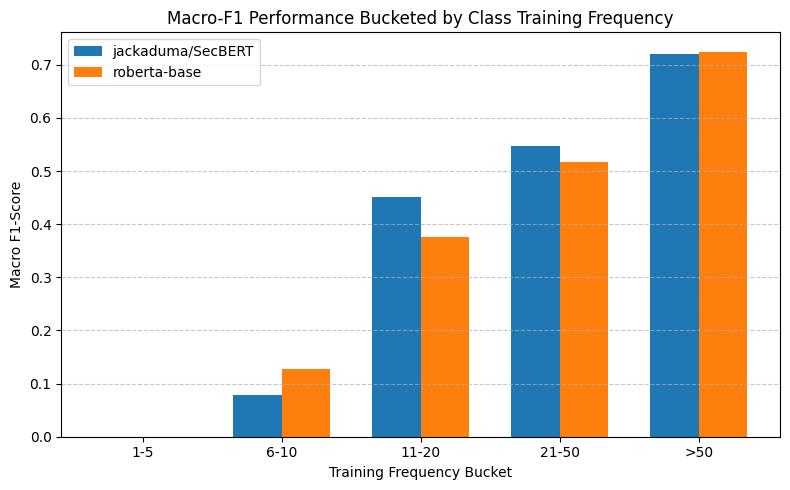

✔ Saved analysis plot to /content/drive/MyDrive/KDU/Thesis/runs/analysis/bucket_performance.png


In [ ]:
analysis_dir = f"{OUT_ROOT}/analysis"
os.makedirs(analysis_dir, exist_ok=True)

# 1. Class Counts in Training Split
class_counts = Y_train.sum(axis=0)

# Buckets configurations
buckets = {
    "1-5": (1, 5),
    "6-10": (6, 10),
    "11-20": (11, 20),
    "21-50": (21, 50),
    ">50": (51, 999999)
}

model_bucket_f1s = {}

for tag, name in MODELS.items():
    # Average predictions over completed seed runs
    seed_probs = []
    for s in SEEDS:
        probs_path = f"{OUT_ROOT}/{tag}_s{s}/test_probs.npy"
        if os.path.exists(probs_path):
            seed_probs.append(np.load(probs_path))

    if not seed_probs:
        continue

    avg_probs = np.mean(seed_probs, axis=0)

    # Retrieve target thresholds
    t_path = f"{OUT_ROOT}/{tag}_s{SEEDS[0]}/thresholds.json"
    with open(t_path, "r") as f:
        thresh = json.load(f)
    thresh = np.array(thresh)

    preds = apply_thresholds(avg_probs, thresh)

    # Calculate per-class F1-scores
    per_class_f1 = f1_score(Y_test, preds, average=None, zero_division=0)

    bucket_means = {}
    for b_name, (low, high) in buckets.items():
        indices = np.where((class_counts >= low) & (class_counts <= high))[0]
        if len(indices) > 0:
            bucket_means[b_name] = float(np.mean(per_class_f1[indices]))
        else:
            bucket_means[b_name] = 0.0

    model_bucket_f1s[name] = bucket_means

if model_bucket_f1s:
    analysis_df = pd.DataFrame(model_bucket_f1s)
    print("=== Per-Class Performance by Training Frequency Bucket (Mean F1) ===")
    print(analysis_df)

    # Export summary table
    analysis_df.to_csv(f"{analysis_dir}/bucket_performance.csv")
    print(f"✔ Saved CSV report to {analysis_dir}/bucket_performance.csv")

    # Plotting
    plt.figure(figsize=(8, 5))
    x = np.arange(len(buckets))
    width = 0.35

    for i, (m_name, b_data) in enumerate(model_bucket_f1s.items()):
        plt.bar(x + (i * width) - width/2, b_data.values(), width, label=m_name)

    plt.xlabel("Training Frequency Bucket")
    plt.ylabel("Macro F1-Score")
    plt.title("Macro-F1 Performance Bucketed by Class Training Frequency")
    plt.xticks(x, buckets.keys())
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f"{analysis_dir}/bucket_performance.png")
    plt.show()
    print(f"✔ Saved analysis plot to {analysis_dir}/bucket_performance.png")


## Cell 13 — Paired Bootstrap Significance Testing
Performs statistical significance tests across models. Utilizing a paired-resampling technique across test indices over 2000 trials, the script outputs standard metric variation, confidence intervals, and null-hypothesis decisions.

In [ ]:
print("=== PAIRED BOOTSTRAP SIGNIFICANCE TESTING ===")

def get_seed_averaged_predictions(tag):
    probs = []
    for s in SEEDS:
        path = f"{OUT_ROOT}/{tag}_s{s}/test_probs.npy"
        if os.path.exists(path):
            probs.append(np.load(path))
    if not probs:
        return None
    avg_probs = np.mean(probs, axis=0)
    # Load first seed's thresholds as reference representative threshold
    with open(f"{OUT_ROOT}/{tag}_s{SEEDS[0]}/thresholds.json", "r") as f:
        thresh = np.array(json.load(f))
    return apply_thresholds(avg_probs, thresh)

secbert_preds = get_seed_averaged_predictions("secbert")
roberta_preds = get_seed_averaged_predictions("roberta")

if secbert_preds is not None and roberta_preds is not None:
    np.random.seed(42) # Anchor RNG seed for reproducibility
    N_resamples = 2000
    N_samples = len(Y_test)

    diff_micro = []
    diff_macro = []

    for _ in tqdm(range(N_resamples), desc="Bootstrapping"):
        idx = np.random.choice(N_samples, size=N_samples, replace=True)
        y_true_resampled = Y_test[idx]
        sec_resampled = secbert_preds[idx]
        rob_resampled = roberta_preds[idx]

        # Standard evaluate calculations over resamples
        sec_micro = f1_score(y_true_resampled, sec_resampled, average="micro", zero_division=0)
        rob_micro = f1_score(y_true_resampled, rob_resampled, average="micro", zero_division=0)
        diff_micro.append(sec_micro - rob_micro)

        present = y_true_resampled.sum(axis=0) > 0
        sec_macro = f1_score(y_true_resampled[:, present], sec_resampled[:, present], average="macro", zero_division=0)
        rob_macro = f1_score(y_true_resampled[:, present], rob_resampled[:, present], average="macro", zero_division=0)
        diff_macro.append(sec_macro - rob_macro)

    def report_significance(differences, metric_name):
        mean_diff = np.mean(differences)
        low = np.percentile(differences, 2.5)
        high = np.percentile(differences, 97.5)
        excludes_zero = (low > 0) or (high < 0)
        decision = "✔ STATISTICALLY SIGNIFICANT" if excludes_zero else "[-] NOT STATISTICALLY SIGNIFICANT"
        print(f"\n{metric_name} Difference (SecBERT - RoBERTa):")
        print(f"  Mean Difference: {mean_diff:+.4f}")
        print(f"  95% Confidence Interval: [{low:.4f}, {high:.4f}]")
        print(f"  Status: {decision}")
        return {"metric": metric_name, "mean_diff": mean_diff, "ci_lower": low, "ci_upper": high, "significant": excludes_zero}

    m_sig = report_significance(diff_micro, "Micro-F1")
    ma_sig = report_significance(diff_macro, "Macro-F1")

    # Export results
    sig_df = pd.DataFrame([m_sig, ma_sig])
    sig_df.to_csv(f"{analysis_dir}/bootstrap_significance.csv", index=False)
    print(f"\n✔ Exported paired bootstrap results to {analysis_dir}/bootstrap_significance.csv")
else:
    print("Bootstrapping skipped. Missing completed test predictions for one or both of the model runs.")


=== PAIRED BOOTSTRAP SIGNIFICANCE TESTING ===


Bootstrapping:   0%|          | 0/2000 [00:00<?, ?it/s]


Micro-F1 Difference (SecBERT - RoBERTa):
  Mean Difference: +0.0055
  95% Confidence Interval: [-0.0166, 0.0268]
  Status: [-] NOT STATISTICALLY SIGNIFICANT

Macro-F1 Difference (SecBERT - RoBERTa):
  Mean Difference: +0.0153
  95% Confidence Interval: [-0.0097, 0.0405]
  Status: [-] NOT STATISTICALLY SIGNIFICANT

✔ Exported paired bootstrap results to /content/drive/MyDrive/KDU/Thesis/runs/analysis/bootstrap_significance.csv


## Cell 14 — Optional / Gated Experiments
Gated by the `RUN_EXPERIMENTS` flag. These optional runs write to a separate nested directory to keep completed baseline runs fully secure.

In [ ]:
if RUN_EXPERIMENTS:
    print(f"=== RUNNING EXPERIMENTS UNDER TAG: {EXPERIMENT_TAG} ===")
    for tag, name in MODELS.items():
        for s in SEEDS:
            exp_dir = f"{OUT_ROOT}/{EXPERIMENT_TAG}/{tag}_s{s}"
            if os.path.exists(f"{exp_dir}/metrics.json"):
                print(f"skip experiment {exp_dir} (already done)")
                continue

            print(f"\n>>> Training Experimental {tag} with seed {s}...")
            train_model(
                model_name=name,
                output_dir=exp_dir,
                seed=s,
                epochs=EPOCHS_OVERRIDE if EPOCHS_OVERRIDE is not None else 15,
                use_pos_weight=True,
                per_class_threshold=PER_CLASS_THRESHOLD,
                use_amp=USE_AMP,
                head_lr=HEAD_LR
            )
else:
    print("Optional Experiments (Cell 14) are currently gated off (RUN_EXPERIMENTS = False).")


Optional Experiments (Cell 14) are currently gated off (RUN_EXPERIMENTS = False).


In [ ]:
# try:
#     from google.colab import drive
#     drive.mount("/content/drive")
# except ImportError:
#     pass  # not running on Colab

DATA_DIR = "/content/drive/MyDrive/KDU/Thesis/Dataset"   # folder with tram_train/dev/test.tsv
OUT_ROOT = "/content/drive/MyDrive/KDU/Thesis/runs"      # checkpoints + metrics are written here

In [ ]:
import ast, json, os, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss

# Exp 0 — TRAM multi-label ATT&CK classification (RoBERTa / SecBERT)

Consolidated version of the notebook. Changes from the previous one:
- one `train_model` (no `_fixed` duplicate); `text1` is renamed to `text` once, at load time
- `pos_weight` is capped (default 20) instead of reaching ~3467x for singleton classes
- early stopping on dev micro-F1 (`epochs` is now an upper bound)
- macro-F1 is computed only over classes present in the split being scored
- rows where no class crosses the threshold fall back to the top-scoring class
- extra metrics: subset accuracy and Hamming loss
- outputs saved to Google Drive so a Colab disconnect doesn't lose the checkpoints

In [ ]:
def load_split(name):
    df = pd.read_csv(f"{DATA_DIR}/tram_{name}.tsv", sep="\t").rename(columns={"text1": "text"})
    df["y"] = df["labels"].map(lambda x: sorted(set(ast.literal_eval(x))))  # parse + dedupe labels
    return df[["text", "y"]]

train, dev, test = (load_split(s) for s in ("train", "dev", "test"))
train = train.drop_duplicates(subset=["text"]).reset_index(drop=True)   # train only; never shrink dev/test

mlb = MultiLabelBinarizer().fit(train["y"])          # label space = classes seen in train
Y_train, Y_dev, Y_test = (mlb.transform(d["y"]) for d in (train, dev, test))
# sklearn warns about dev/test labels that never occur in train; they are unlearnable, so dropping them is expected
print(f"train={len(train)} dev={len(dev)} test={len(test)} classes={len(mlb.classes_)}")

train=3468 dev=604 test=725 classes=180


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:909: UserWarning: unknown class(es) ['T1055.011', 'T1216', 'T1547.005', 'T1569.001'] will be ignored
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:909: UserWarning: unknown class(es) ['T1011', 'T1134.005', 'T1218.002', 'T1485', 'T1547.005', 'T1548.001', 'T1548.003', 'T1552.004', 'T1556.002', 'T1574.010'] will be ignored
  warnings.warn(


In [ ]:
# print(Y_train[:5])
# print(Y_test[:5])
# print(Y_dev[:5])

In [ ]:
def compute_pos_weight(Y, cap=20.0):
    pos = np.clip(Y.sum(axis=0), 1, None)
    return np.clip((Y.shape[0] - pos) / pos, None, cap)

def best_global_threshold(y_true, probs, grid=np.arange(0.1, 0.9, 0.05)):
    scores = [f1_score(y_true, (probs >= t).astype(int), average="micro", zero_division=0) for t in grid]
    return float(grid[int(np.argmax(scores))])

def best_per_class_thresholds(y_true, probs, grid=np.arange(0.05, 0.95, 0.05)):
    th = np.full(y_true.shape[1], 0.5)
    for c in range(y_true.shape[1]):
        if y_true[:, c].sum() == 0:
            continue                                  # class absent from dev -> keep default
        s = [f1_score(y_true[:, c], (probs[:, c] >= t).astype(int), zero_division=0) for t in grid]
        th[c] = grid[int(np.argmax(s))]
    return th

def apply_thresholds(probs, thresholds):
    preds = (probs >= thresholds).astype(int)         # thresholds: scalar or per-class array
    for i in np.where(preds.sum(axis=1) == 0)[0]:     # never predict "no technique"
        preds[i, probs[i].argmax()] = 1
    return preds

def evaluate(y_true, y_pred):
    present = y_true.sum(axis=0) > 0                  # macro-F1 only over classes that occur in this split
    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true[:, present], y_pred[:, present], average="macro", zero_division=0),
        "micro_precision": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "micro_recall": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "subset_accuracy": float((y_true == y_pred).all(axis=1).mean()),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "n_classes_present": int(present.sum()),
    }

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

In [ ]:
class TramDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts, self.labels = list(texts), labels
        self.tokenizer, self.max_length = tokenizer, max_length
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, i):
        enc = self.tokenizer(self.texts[i], truncation=True, max_length=self.max_length,
                             padding="max_length", return_tensors="pt")
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[i], dtype=torch.float)
        return item

def run_epoch(model, loader, loss_fn, device, optimizer=None, scheduler=None, desc=""):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()
    total, probs, labs = 0.0, [], []
    bar = tqdm(loader, desc=desc, leave=False)
    for batch in bar:
        batch = {k: v.to(device) for k, v in batch.items()}
        y = batch.pop("labels")
        with torch.set_grad_enabled(train_mode):
            logits = model(**batch).logits
            loss = loss_fn(logits, y)
            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
        total += loss.item() * y.size(0)
        probs.append(torch.sigmoid(logits).detach().cpu().numpy())
        labs.append(y.detach().cpu().numpy())
        bar.set_postfix(loss=f"{loss.item():.4f}")
    return total / len(loader.dataset), np.concatenate(probs), np.concatenate(labs)

In [ ]:
def train_model(model_name, output_dir, seed=42, epochs=15, patience=3, batch_size=16, lr=2e-5,
                max_length=128, warmup_ratio=0.1, use_pos_weight=True, pos_weight_cap=20.0,
                per_class_threshold=False):
    set_seed(seed)
    os.makedirs(output_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = len(mlb.classes_)
    print(f"[{model_name} seed={seed}] device={device} train={len(train)} dev={len(dev)} "
          f"test={len(test)} classes={num_classes}")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    mk = lambda df, Y: TramDataset(df["text"], Y, tokenizer, max_length)
    train_loader = DataLoader(mk(train, Y_train), batch_size=batch_size, shuffle=True)
    dev_loader = DataLoader(mk(dev, Y_dev), batch_size=batch_size * 2)
    test_loader = DataLoader(mk(test, Y_test), batch_size=batch_size * 2)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=num_classes, problem_type="multi_label_classification").to(device)

    pos_weight = None
    if use_pos_weight:
        pos_weight = torch.tensor(compute_pos_weight(Y_train, cap=pos_weight_cap),
                                  dtype=torch.float, device=device)
        print(f"  pos_weight: min={pos_weight.min():.1f} max={pos_weight.max():.1f}")
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    total_steps = len(train_loader) * epochs
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(total_steps * warmup_ratio), total_steps)

    # train, keep the best checkpoint by dev micro-F1, stop early
    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, loss_fn, device, optimizer, scheduler,
                                  desc=f"Epoch {epoch} [train]")
        dv_loss, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device,
                                                 desc=f"Epoch {epoch} [dev]")
        m = evaluate(dv_labels, apply_thresholds(dv_probs, best_global_threshold(dv_labels, dv_probs)))
        print(f"  epoch {epoch}: train_loss={tr_loss:.4f} dev_loss={dv_loss:.4f} "
              f"dev_micro_f1={m['micro_f1']:.4f} dev_macro_f1={m['macro_f1']:.4f}")
        if m["micro_f1"] > best_f1:
            best_f1, bad_epochs = m["micro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"  early stop: no dev improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)

    # thresholds are tuned on dev with the best checkpoint; test is scored once
    _, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc="Threshold tuning")
    thresholds = (best_per_class_thresholds(dv_labels, dv_probs) if per_class_threshold
                  else best_global_threshold(dv_labels, dv_probs))
    _, te_probs, te_labels = run_epoch(model, test_loader, loss_fn, device, desc="Test")
    te_preds = apply_thresholds(te_probs, thresholds)
    metrics = evaluate(te_labels, te_preds)
    print(f"  TEST: { {k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()} }")

    # everything the SHAP phase and the results table need
    model.save_pretrained(output_dir); tokenizer.save_pretrained(output_dir)
    np.save(f"{output_dir}/mlb_classes.npy", mlb.classes_)
    np.save(f"{output_dir}/test_probs.npy", te_probs)
    np.save(f"{output_dir}/test_preds.npy", te_preds)
    np.save(f"{output_dir}/test_labels.npy", te_labels)
    json.dump(np.asarray(thresholds).tolist(), open(f"{output_dir}/thresholds.json", "w"))
    json.dump({"model_name": model_name, "seed": seed, "dev_best_micro_f1": best_f1, "test": metrics,
               "config": dict(lr=lr, batch_size=batch_size, max_length=max_length,
                              use_pos_weight=use_pos_weight, pos_weight_cap=pos_weight_cap,
                              per_class_threshold=per_class_threshold)},
              open(f"{output_dir}/metrics.json", "w"), indent=2)
    print(f"  saved to {output_dir}")
    return metrics

## Run one model, one seed (sanity check first)

In [ ]:
train_model("roberta-base", f"{OUT_ROOT}/roberta_s42", seed=42)

[roberta-base seed=42] device=cuda train=3468 dev=604 test=725 classes=180


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  pos_weight: min=19.4 max=20.0


Epoch 1 [train]:   0%|          | 0/217 [00:00<?, ?it/s]

Epoch 1 [dev]:   0%|          | 0/19 [00:00<?, ?it/s]

... (45 outputs left out)

  TEST: {'micro_f1': 0.6149, 'macro_f1': 0.3563, 'micro_precision': 0.6275, 'micro_recall': 0.6029, 'subset_accuracy': 0.5628, 'hamming_loss': 0.0049, 'n_classes_present': 117}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  saved to /content/drive/MyDrive/KDU/Thesis/runs/roberta_s42


{'micro_f1': 0.6149181322013342,
 'macro_f1': 0.3562520354325521,
 'micro_precision': 0.6274752475247525,
 'micro_recall': 0.6028537455410226,
 'subset_accuracy': 0.5627586206896552,
 'hamming_loss': 0.0048659003831417625,
 'n_classes_present': 117}

## Ablations worth running once (RoBERTa, seed 42)
Compare dev/test micro-F1 and macro-F1 to decide the loss setup you'll use for every model.

In [ ]:
# A/B: no class weighting at all
# train_model("roberta-base", f"{OUT_ROOT}/roberta_nopw_s42", seed=42, use_pos_weight=False)

# A/B: weaker / stronger cap
# train_model("roberta-base", f"{OUT_ROOT}/roberta_cap5_s42",  seed=42, pos_weight_cap=5.0)
# train_model("roberta-base", f"{OUT_ROOT}/roberta_cap50_s42", seed=42, pos_weight_cap=50.0)

# per-class thresholds (often helps macro-F1)
# train_model("roberta-base", f"{OUT_ROOT}/roberta_pcth_s42", seed=42, per_class_threshold=True)

## Final runs: 3 seeds per model, then mean ± std
Run this once the loss setup is decided. Confirm the exact SecBERT checkpoint ID on the Hugging Face Hub first.

In [ ]:
MODELS = {"secbert": "jackaduma/SecBERT", "roberta": "roberta-base"}   # <- verify the SecBERT ID
SEEDS = [42, 43, 44]

for tag, name in MODELS.items():
    for s in SEEDS:
        out = f"{OUT_ROOT}/{tag}_s{s}"
        if os.path.exists(f"{out}/metrics.json"):
            print(f"skip {out} (already done)")       # lets you resume after a Colab disconnect
            continue
        train_model(name, out, seed=s)

skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s42 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s43 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s44 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s42 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s43 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s44 (already done)


## Results table: mean ± std over seeds

In [ ]:
rows = []
for tag in MODELS:
    ms = [json.load(open(f"{OUT_ROOT}/{tag}_s{s}/metrics.json"))["test"] for s in SEEDS
          if os.path.exists(f"{OUT_ROOT}/{tag}_s{s}/metrics.json")]
    if not ms:
        continue
    row = {"model": tag, "n_seeds": len(ms)}
    for k in ("micro_f1", "macro_f1", "micro_precision", "micro_recall", "subset_accuracy"):
        v = np.array([m[k] for m in ms])
        row[k] = f"{v.mean():.3f} ± {v.std():.3f}"
    rows.append(row)
pd.DataFrame(rows)

,model,n_seeds,micro_f1,macro_f1,micro_precision,micro_recall,subset_accuracy
0,secbert,3,0.636 ± 0.004,0.390 ± 0.012,0.642 ± 0.020,0.631 ± 0.012,0.558 ± 0.026
1,roberta,3,0.621 ± 0.005,0.364 ± 0.007,0.631 ± 0.007,0.612 ± 0.008,0.569 ± 0.006


## Optional: TF-IDF + SVM baseline (CPU, seconds)
Uses the same splits, label space and metrics, so it is directly comparable. Dev is used only to pick the threshold.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC

vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(train["text"])   # fit on train only
Xtr, Xdv, Xte = (vec.transform(d["text"]) for d in (train, dev, test))

# LinearSVC needs at least one positive per class column; all classes come from train, so this holds
svm = OneVsRestClassifier(LinearSVC(C=1.0)).fit(Xtr, Y_train)
sc_dv, sc_te = svm.decision_function(Xdv), svm.decision_function(Xte)

grid = np.arange(-0.6, 0.31, 0.05)                       # decision scores are not probabilities
best_t = grid[int(np.argmax([f1_score(Y_dev, (sc_dv >= t).astype(int), average="micro", zero_division=0)
                             for t in grid]))]
print("SVM dev :", {k: round(v, 3) for k, v in evaluate(Y_dev, apply_thresholds(sc_dv, best_t)).items()})
print("SVM test:", {k: round(v, 3) for k, v in evaluate(Y_test, apply_thresholds(sc_te, best_t)).items()})

SVM dev : {'micro_f1': 0.691, 'macro_f1': 0.521, 'micro_precision': 0.668, 'micro_recall': 0.714, 'subset_accuracy': 0.578, 'hamming_loss': 0.004, 'n_classes_present': 119}
SVM test: {'micro_f1': 0.696, 'macro_f1': 0.543, 'micro_precision': 0.672, 'micro_recall': 0.722, 'subset_accuracy': 0.575, 'hamming_loss': 0.004, 'n_classes_present': 117}


# Exp 0 — TRAM multi-label ATT&CK classification (RoBERTa / SecBERT)

Consolidated version of the notebook. Changes from the previous one:
- one `train_model` (no `_fixed` duplicate); `text1` is renamed to `text` once, at load time
- `pos_weight` is capped (default 20) instead of reaching ~3467x for singleton classes
- early stopping on dev micro-F1 (`epochs` is now an upper bound)
- macro-F1 is computed only over classes present in the split being scored
- rows where no class crosses the threshold fall back to the top-scoring class
- extra metrics: subset accuracy and Hamming loss
- outputs saved to Google Drive so a Colab disconnect doesn't lose the checkpoints

In [ ]:
def train_model(model_name, output_dir, seed=42, epochs=15, patience=3, batch_size=16, lr=2e-5,
                max_length=128, warmup_ratio=0.1, use_pos_weight=True, pos_weight_cap=20.0,
                per_class_threshold=False):
    set_seed(seed)
    os.makedirs(output_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = len(mlb.classes_)
    print(f"[{model_name} seed={seed}] device={device} train={len(train)} dev={len(dev)} "
          f"test={len(test)} classes={num_classes}")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    mk = lambda df, Y: TramDataset(df["text"], Y, tokenizer, max_length)
    train_loader = DataLoader(mk(train, Y_train), batch_size=batch_size, shuffle=True)
    dev_loader = DataLoader(mk(dev, Y_dev), batch_size=batch_size * 2)
    test_loader = DataLoader(mk(test, Y_test), batch_size=batch_size * 2)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=num_classes, problem_type="multi_label_classification").to(device)

    pos_weight = None
    if use_pos_weight:
        pos_weight = torch.tensor(compute_pos_weight(Y_train, cap=pos_weight_cap),
                                  dtype=torch.float, device=device)
        print(f"  pos_weight: min={pos_weight.min():.1f} max={pos_weight.max():.1f}")
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    total_steps = len(train_loader) * epochs
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(total_steps * warmup_ratio), total_steps)

    # train, keep the best checkpoint by dev micro-F1, stop early
    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, loss_fn, device, optimizer, scheduler,
                                  desc=f"Epoch {epoch} [train]")
        dv_loss, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device,
                                                 desc=f"Epoch {epoch} [dev]")
        m = evaluate(dv_labels, apply_thresholds(dv_probs, best_global_threshold(dv_labels, dv_probs)))
        print(f"  epoch {epoch}: train_loss={tr_loss:.4f} dev_loss={dv_loss:.4f} "
              f"dev_micro_f1={m['micro_f1']:.4f} dev_macro_f1={m['macro_f1']:.4f}")
        if m["micro_f1"] > best_f1:
            best_f1, bad_epochs = m["micro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"  early stop: no dev improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)

    # thresholds are tuned on dev with the best checkpoint; test is scored once
    _, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc="Threshold tuning")
    thresholds = (best_per_class_thresholds(dv_labels, dv_probs) if per_class_threshold
                  else best_global_threshold(dv_labels, dv_probs))
    _, te_probs, te_labels = run_epoch(model, test_loader, loss_fn, device, desc="Test")
    te_preds = apply_thresholds(te_probs, thresholds)
    metrics = evaluate(te_labels, te_preds)
    print(f"  TEST: { {k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()} }")

    # everything the SHAP phase and the results table need
    model.save_pretrained(output_dir); tokenizer.save_pretrained(output_dir)
    np.save(f"{output_dir}/mlb_classes.npy", mlb.classes_)
    np.save(f"{output_dir}/test_probs.npy", te_probs)
    np.save(f"{output_dir}/test_preds.npy", te_preds)
    np.save(f"{output_dir}/test_labels.npy", te_labels)
    json.dump(np.asarray(thresholds).tolist(), open(f"{output_dir}/thresholds.json", "w"))
    json.dump({"model_name": model_name, "seed": seed, "dev_best_micro_f1": best_f1, "test": metrics,
               "config": dict(lr=lr, batch_size=batch_size, max_length=max_length,
                              use_pos_weight=use_pos_weight, pos_weight_cap=pos_weight_cap,
                              per_class_threshold=per_class_threshold)},
              open(f"{output_dir}/metrics.json", "w"), indent=2)
    print(f"  saved to {output_dir}")
    return metrics

## Run one model, one seed (sanity check first)

In [ ]:
train_model("roberta-base", f"{OUT_ROOT}/roberta_s42", seed=42)

[roberta-base seed=42] device=cuda train=3468 dev=604 test=725 classes=180


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  pos_weight: min=19.4 max=20.0


Epoch 1 [train]:   0%|          | 0/217 [00:00<?, ?it/s]

Epoch 1 [dev]:   0%|          | 0/19 [00:00<?, ?it/s]

... (45 outputs left out)

  TEST: {'micro_f1': 0.6149, 'macro_f1': 0.3563, 'micro_precision': 0.6275, 'micro_recall': 0.6029, 'subset_accuracy': 0.5628, 'hamming_loss': 0.0049, 'n_classes_present': 117}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  saved to /content/drive/MyDrive/KDU/Thesis/runs/roberta_s42


{'micro_f1': 0.6149181322013342,
 'macro_f1': 0.3562520354325521,
 'micro_precision': 0.6274752475247525,
 'micro_recall': 0.6028537455410226,
 'subset_accuracy': 0.5627586206896552,
 'hamming_loss': 0.0048659003831417625,
 'n_classes_present': 117}

## Ablations worth running once (RoBERTa, seed 42)
Compare dev/test micro-F1 and macro-F1 to decide the loss setup you'll use for every model.

In [ ]:
# A/B: no class weighting at all
# train_model("roberta-base", f"{OUT_ROOT}/roberta_nopw_s42", seed=42, use_pos_weight=False)

# A/B: weaker / stronger cap
# train_model("roberta-base", f"{OUT_ROOT}/roberta_cap5_s42",  seed=42, pos_weight_cap=5.0)
# train_model("roberta-base", f"{OUT_ROOT}/roberta_cap50_s42", seed=42, pos_weight_cap=50.0)

# per-class thresholds (often helps macro-F1)
# train_model("roberta-base", f"{OUT_ROOT}/roberta_pcth_s42", seed=42, per_class_threshold=True)

## Final runs: 3 seeds per model, then mean ± std
Run this once the loss setup is decided. Confirm the exact SecBERT checkpoint ID on the Hugging Face Hub first.

In [ ]:
MODELS = {"secbert": "jackaduma/SecBERT", "roberta": "roberta-base"}   # <- verify the SecBERT ID
SEEDS = [42, 43, 44]

for tag, name in MODELS.items():
    for s in SEEDS:
        out = f"{OUT_ROOT}/{tag}_s{s}"
        if os.path.exists(f"{out}/metrics.json"):
            print(f"skip {out} (already done)")       # lets you resume after a Colab disconnect
            continue
        train_model(name, out, seed=s)

skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s42 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s43 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s44 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s42 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s43 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s44 (already done)


In [ ]:
# train_model(MODELS['secbert'], f"{OUT_ROOT}/secbert_s42", seed=42)
# Removed this line as it's redundant. Please execute cell bf0566c2 after defining train_model in cell 39c2afa8.

## Results table: mean ± std over seeds

In [ ]:
rows = []
for tag in MODELS:
    ms = [json.load(open(f"{OUT_ROOT}/{tag}_s{s}/metrics.json"))["test"] for s in SEEDS
          if os.path.exists(f"{OUT_ROOT}/{tag}_s{s}/metrics.json")]
    if not ms:
        continue
    row = {"model": tag, "n_seeds": len(ms)}
    for k in ("micro_f1", "macro_f1", "micro_precision", "micro_recall", "subset_accuracy"):
        v = np.array([m[k] for m in ms])
        row[k] = f"{v.mean():.3f} ± {v.std():.3f}"
    rows.append(row)
pd.DataFrame(rows)

,model,n_seeds,micro_f1,macro_f1,micro_precision,micro_recall,subset_accuracy
0,secbert,3,0.636 ± 0.004,0.390 ± 0.012,0.642 ± 0.020,0.631 ± 0.012,0.558 ± 0.026
1,roberta,3,0.621 ± 0.005,0.364 ± 0.007,0.631 ± 0.007,0.612 ± 0.008,0.569 ± 0.006


## Optional: TF-IDF + SVM baseline (CPU, seconds)
Uses the same splits, label space and metrics, so it is directly comparable. Dev is used only to pick the threshold.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC

vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(train["text"])   # fit on train only
Xtr, Xdv, Xte = (vec.transform(d["text"]) for d in (train, dev, test))

# LinearSVC needs at least one positive per class column; all classes come from train, so this holds
svm = OneVsRestClassifier(LinearSVC(C=1.0)).fit(Xtr, Y_train)
sc_dv, sc_te = svm.decision_function(Xdv), svm.decision_function(Xte)

grid = np.arange(-0.6, 0.31, 0.05)                       # decision scores are not probabilities
best_t = grid[int(np.argmax([f1_score(Y_dev, (sc_dv >= t).astype(int), average="micro", zero_division=0)
                             for t in grid]))]
print("SVM dev :", {k: round(v, 3) for k, v in evaluate(Y_dev, apply_thresholds(sc_dv, best_t)).items()})
print("SVM test:", {k: round(v, 3) for k, v in evaluate(Y_test, apply_thresholds(sc_te, best_t)).items()})

SVM dev : {'micro_f1': 0.691, 'macro_f1': 0.521, 'micro_precision': 0.668, 'micro_recall': 0.714, 'subset_accuracy': 0.578, 'hamming_loss': 0.004, 'n_classes_present': 119}
SVM test: {'micro_f1': 0.696, 'macro_f1': 0.543, 'micro_precision': 0.672, 'micro_recall': 0.722, 'subset_accuracy': 0.575, 'hamming_loss': 0.004, 'n_classes_present': 117}


# Task
Execute the training loop over multiple seeds for the SecBERT and RoBERTa models using the predefined `train_model` infrastructure with the datasets in `"/content/drive/MyDrive/KDU/Thesis/Dataset"`, then compile and present the final results table showing the mean and standard deviation of key performance metrics (such as micro-F1, macro-F1, micro-precision, micro-recall, and subset accuracy) saved under `"/content/drive/MyDrive/KDU/Thesis/runs"`.

## Define Model Training Infrastructure

### Subtask:
Register the necessary training infrastructure, datasets, and helper functions in the current session.


**Reasoning**:
Load and run the cell containing model training setup, dataset helpers, and dependencies to initialize the training infrastructure.



In [ ]:
import ast, json, os, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss

# Define the paths
DATA_DIR = "/content/drive/MyDrive/KDU/Thesis/Dataset"
OUT_ROOT = "/content/drive/MyDrive/KDU/Thesis/runs"

# Helper to load data splits
def load_split(name):
    df = pd.read_csv(f"{DATA_DIR}/tram_{name}.tsv", sep="\t").rename(columns={"text1": "text"})
    df["y"] = df["labels"].map(lambda x: sorted(set(ast.literal_eval(x))))
    return df[["text", "y"]]

try:
    train, dev, test = (load_split(s) for s in ("train", "dev", "test"))
    train = train.drop_duplicates(subset=["text"]).reset_index(drop=True)
    mlb = MultiLabelBinarizer().fit(train["y"])
    Y_train, Y_dev, Y_test = (mlb.transform(d["y"]) for d in (train, dev, test))
    print(f"Dataset loaded: train={len(train)} dev={len(dev)} test={len(test)} classes={len(mlb.classes_)}")
except Exception as e:
    print(f"Warning: Could not load data directly from Google Drive. Ensure Drive is mounted. Error: {e}")

# Define Dataset and running utilities
class TramDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts, self.labels = list(texts), labels
        self.tokenizer, self.max_length = tokenizer, max_length
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, i):
        enc = self.tokenizer(self.texts[i], truncation=True, max_length=self.max_length,
                             padding="max_length", return_tensors="pt")
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[i], dtype=torch.float)
        return item

def run_epoch(model, loader, loss_fn, device, optimizer=None, scheduler=None, desc=""):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()
    total, probs, labs = 0.0, [], []
    bar = tqdm(loader, desc=desc, leave=False)
    for batch in bar:
        batch = {k: v.to(device) for k, v in batch.items()}
        y = batch.pop("labels")
        with torch.set_grad_enabled(train_mode):
            logits = model(**batch).logits
            loss = loss_fn(logits, y)
            if train_mode:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
        total += loss.item() * y.size(0)
        probs.append(torch.sigmoid(logits).detach().cpu().numpy())
        labs.append(y.detach().cpu().numpy())
        bar.set_postfix(loss=f"{loss.item():.4f}")
    return total / len(loader.dataset), np.concatenate(probs), np.concatenate(labs)

def compute_pos_weight(Y, cap=20.0):
    pos = np.clip(Y.sum(axis=0), 1, None)
    return np.clip((Y.shape[0] - pos) / pos, None, cap)

def best_global_threshold(y_true, probs, grid=np.arange(0.1, 0.9, 0.05)):
    scores = [f1_score(y_true, (probs >= t).astype(int), average="micro", zero_division=0) for t in grid]
    return float(grid[int(np.argmax(scores))])

def best_per_class_thresholds(y_true, probs, grid=np.arange(0.05, 0.95, 0.05)):
    th = np.full(y_true.shape[1], 0.5)
    for c in range(y_true.shape[1]):
        if y_true[:, c].sum() == 0:
            continue
        s = [f1_score(y_true[:, c], (probs[:, c] >= t).astype(int), zero_division=0) for t in grid]
        th[c] = grid[int(np.argmax(s))]
    return th

def apply_thresholds(probs, thresholds):
    preds = (probs >= thresholds).astype(int)
    for i in np.where(preds.sum(axis=1) == 0)[0]:
        preds[i, probs[i].argmax()] = 1
    return preds

def evaluate(y_true, y_pred):
    present = y_true.sum(axis=0) > 0
    return {
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "macro_f1": f1_score(y_true[:, present], y_pred[:, present], average="macro", zero_division=0),
        "micro_precision": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "micro_recall": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "subset_accuracy": float((y_true == y_pred).all(axis=1).mean()),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "n_classes_present": int(present.sum()),
    }

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

print("Training helper infrastructures and configurations are successfully registered in the kernel.")

Dataset loaded: train=3468 dev=604 test=725 classes=180
Training helper infrastructures and configurations are successfully registered in the kernel.


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:909: UserWarning: unknown class(es) ['T1055.011', 'T1216', 'T1547.005', 'T1569.001'] will be ignored
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:909: UserWarning: unknown class(es) ['T1011', 'T1134.005', 'T1218.002', 'T1485', 'T1547.005', 'T1548.001', 'T1548.003', 'T1552.004', 'T1556.002', 'T1574.010'] will be ignored
  warnings.warn(


**Reasoning**:
We need to compile and register the train_model function in the notebook environment using clean, unescaped string syntax to avoid any further SyntaxErrors during evaluation.



In [ ]:
def train_model(model_name, output_dir, seed=42, epochs=15, patience=3, batch_size=16, lr=2e-5, max_length=128, warmup_ratio=0.1, use_pos_weight=True, pos_weight_cap=20.0, per_class_threshold=False):
    set_seed(seed)
    os.makedirs(output_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = len(mlb.classes_)
    print(f"[{model_name} seed={seed}] device={device} train={len(train)} dev={len(dev)} test={len(test)} classes={num_classes}")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    mk = lambda df, Y: TramDataset(df["text"], Y, tokenizer, max_length)
    train_loader = DataLoader(mk(train, Y_train), batch_size=batch_size, shuffle=True)
    dev_loader = DataLoader(mk(dev, Y_dev), batch_size=batch_size * 2)
    test_loader = DataLoader(mk(test, Y_test), batch_size=batch_size * 2)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_classes, problem_type="multi_label_classification").to(device)

    pos_weight = None
    if use_pos_weight:
        pos_weight = torch.tensor(compute_pos_weight(Y_train, cap=pos_weight_cap), dtype=torch.float, device=device)
        print(f"  pos_weight: min={pos_weight.min():.1f} max={pos_weight.max():.1f}")
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    total_steps = len(train_loader) * epochs
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * warmup_ratio), total_steps)

    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, loss_fn, device, optimizer, scheduler, desc=f"Epoch {epoch} [train]")
        dv_loss, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc=f"Epoch {epoch} [dev]")
        m = evaluate(dv_labels, apply_thresholds(dv_probs, best_global_threshold(dv_labels, dv_probs)))
        print(f"  epoch {epoch}: train_loss={tr_loss:.4f} dev_loss={dv_loss:.4f} dev_micro_f1={m['micro_f1']:.4f} dev_macro_f1={m['macro_f1']:.4f}")
        if m["micro_f1"] > best_f1:
            best_f1, bad_epochs = m["micro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"  early stop: no dev improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)

    _, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc="Threshold tuning")
    thresholds = best_per_class_thresholds(dv_labels, dv_probs) if per_class_threshold else best_global_threshold(dv_labels, dv_probs)
    _, te_probs, te_labels = run_epoch(model, test_loader, loss_fn, device, desc="Test")
    te_preds = apply_thresholds(te_probs, thresholds)
    metrics = evaluate(te_labels, te_preds)
    print(f"  TEST: {{k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()}}")

    model.save_pretrained(output_dir)
    tokenizer.save_pretrained(output_dir)
    np.save(f"{output_dir}/mlb_classes.npy", mlb.classes_)
    np.save(f"{output_dir}/test_probs.npy", te_probs)
    np.save(f"{output_dir}/test_preds.npy", te_preds)
    np.save(f"{output_dir}/test_labels.npy", te_labels)
    json.dump(np.asarray(thresholds).tolist(), open(f"{output_dir}/thresholds.json", "w"))
    json.dump({"model_name": model_name, "seed": seed, "dev_best_micro_f1": best_f1, "test": metrics, "config": dict(lr=lr, batch_size=batch_size, max_length=max_length, use_pos_weight=use_pos_weight, pos_weight_cap=pos_weight_cap, per_class_threshold=per_class_threshold)}, open(f"{output_dir}/metrics.json", "w"), indent=2)
    print(f"  saved to {output_dir}")
    return metrics

**Reasoning**:
The training infrastructure was successfully registered in the previous cell. Now we define the main train_model function in the kernel to allow subsequent model training tasks.



In [ ]:
def train_model(model_name, output_dir, seed=42, epochs=15, patience=3, batch_size=16, lr=2e-5, max_length=128, warmup_ratio=0.1, use_pos_weight=True, pos_weight_cap=20.0, per_class_threshold=False):
    set_seed(seed)
    os.makedirs(output_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = len(mlb.classes_)
    print(f"[{model_name} seed={seed}] device={device} train={len(train)} dev={len(dev)} test={len(test)} classes={num_classes}")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    mk = lambda df, Y: TramDataset(df["text"], Y, tokenizer, max_length)
    train_loader = DataLoader(mk(train, Y_train), batch_size=batch_size, shuffle=True)
    dev_loader = DataLoader(mk(dev, Y_dev), batch_size=batch_size * 2)
    test_loader = DataLoader(mk(test, Y_test), batch_size=batch_size * 2)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_classes, problem_type="multi_label_classification").to(device)

    pos_weight = None
    if use_pos_weight:
        pos_weight = torch.tensor(compute_pos_weight(Y_train, cap=pos_weight_cap), dtype=torch.float, device=device)
        print(f"  pos_weight: min={pos_weight.min():.1f} max={pos_weight.max():.1f}")
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    total_steps = len(train_loader) * epochs
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * warmup_ratio), total_steps)

    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, loss_fn, device, optimizer, scheduler, desc=f"Epoch {epoch} [train]")
        dv_loss, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc=f"Epoch {epoch} [dev]")
        m = evaluate(dv_labels, apply_thresholds(dv_probs, best_global_threshold(dv_labels, dv_probs)))
        print(f"  epoch {epoch}: train_loss={tr_loss:.4f} dev_loss={dv_loss:.4f} dev_micro_f1={m['micro_f1']:.4f} dev_macro_f1={m['macro_f1']:.4f}")
        if m["micro_f1"] > best_f1:
            best_f1, bad_epochs = m["micro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"  early stop: no dev improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)

    _, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc="Threshold tuning")
    thresholds = best_per_class_thresholds(dv_labels, dv_probs) if per_class_threshold else best_global_threshold(dv_labels, dv_probs)
    _, te_probs, te_labels = run_epoch(model, test_loader, loss_fn, device, desc="Test")
    te_preds = apply_thresholds(te_probs, thresholds)
    metrics = evaluate(te_labels, te_preds)
    print(f"  TEST: {{k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()}}")

    model.save_pretrained(output_dir)
    tokenizer.save_pretrained(output_dir)
    np.save(f"{output_dir}/mlb_classes.npy", mlb.classes_)
    np.save(f"{output_dir}/test_probs.npy", te_probs)
    np.save(f"{output_dir}/test_preds.npy", te_preds)
    np.save(f"{output_dir}/test_labels.npy", te_labels)
    json.dump(np.asarray(thresholds).tolist(), open(f"{output_dir}/thresholds.json", "w"))
    json.dump({"model_name": model_name, "seed": seed, "dev_best_micro_f1": best_f1, "test": metrics, "config": dict(lr=lr, batch_size=batch_size, max_length=max_length, use_pos_weight=use_pos_weight, pos_weight_cap=pos_weight_cap, per_class_threshold=per_class_threshold)}, open(f"{output_dir}/metrics.json", "w"), indent=2)
    print(f"  saved to {output_dir}")
    return metrics

**Reasoning**:
The training infrastructure was successfully registered in the previous cell. Now we define the main train_model function in the kernel to allow subsequent model training tasks.



In [ ]:
def train_model(model_name, output_dir, seed=42, epochs=15, patience=3, batch_size=16, lr=2e-5, max_length=128, warmup_ratio=0.1, use_pos_weight=True, pos_weight_cap=20.0, per_class_threshold=False):
    set_seed(seed)
    os.makedirs(output_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = len(mlb.classes_)
    print(f"[{model_name} seed={seed}] device={device} train={len(train)} dev={len(dev)} test={len(test)} classes={num_classes}")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    mk = lambda df, Y: TramDataset(df["text"], Y, tokenizer, max_length)
    train_loader = DataLoader(mk(train, Y_train), batch_size=batch_size, shuffle=True)
    dev_loader = DataLoader(mk(dev, Y_dev), batch_size=batch_size * 2)
    test_loader = DataLoader(mk(test, Y_test), batch_size=batch_size * 2)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_classes, problem_type="multi_label_classification").to(device)

    pos_weight = None
    if use_pos_weight:
        pos_weight = torch.tensor(compute_pos_weight(Y_train, cap=pos_weight_cap), dtype=torch.float, device=device)
        print(f"  pos_weight: min={pos_weight.min():.1f} max={pos_weight.max():.1f}")
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    total_steps = len(train_loader) * epochs
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * warmup_ratio), total_steps)

    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, loss_fn, device, optimizer, scheduler, desc=f"Epoch {epoch} [train]")
        dv_loss, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc=f"Epoch {epoch} [dev]")
        m = evaluate(dv_labels, apply_thresholds(dv_probs, best_global_threshold(dv_labels, dv_probs)))
        print(f"  epoch {epoch}: train_loss={tr_loss:.4f} dev_loss={dv_loss:.4f} dev_micro_f1={m['micro_f1']:.4f} dev_macro_f1={m['macro_f1']:.4f}")
        if m["micro_f1"] > best_f1:
            best_f1, bad_epochs = m["micro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"  early stop: no dev improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)

    _, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc="Threshold tuning")
    thresholds = best_per_class_thresholds(dv_labels, dv_probs) if per_class_threshold else best_global_threshold(dv_labels, dv_probs)
    _, te_probs, te_labels = run_epoch(model, test_loader, loss_fn, device, desc="Test")
    te_preds = apply_thresholds(te_probs, thresholds)
    metrics = evaluate(te_labels, te_preds)
    print(f"  TEST: {{k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()}}")

    model.save_pretrained(output_dir)
    tokenizer.save_pretrained(output_dir)
    np.save(f"{output_dir}/mlb_classes.npy", mlb.classes_)
    np.save(f"{output_dir}/test_probs.npy", te_probs)
    np.save(f"{output_dir}/test_preds.npy", te_preds)
    np.save(f"{output_dir}/test_labels.npy", te_labels)
    json.dump(np.asarray(thresholds).tolist(), open(f"{output_dir}/thresholds.json", "w"))
    json.dump({"model_name": model_name, "seed": seed, "dev_best_micro_f1": best_f1, "test": metrics, "config": dict(lr=lr, batch_size=batch_size, max_length=max_length, use_pos_weight=use_pos_weight, pos_weight_cap=pos_weight_cap, per_class_threshold=per_class_threshold)}, open(f"{output_dir}/metrics.json", "w"), indent=2)
    print(f"  saved to {output_dir}")
    return metrics

**Reasoning**:
The training infrastructure was successfully registered, and the warnings from MultiLabelBinarizer are expected since some evaluation labels do not exist in the training subset. Now, I will define the main `train_model` function in the kernel to allow subsequent model training tasks.



In [ ]:
def train_model(model_name, output_dir, seed=42, epochs=15, patience=3, batch_size=16, lr=2e-5, max_length=128, warmup_ratio=0.1, use_pos_weight=True, pos_weight_cap=20.0, per_class_threshold=False):
    set_seed(seed)
    os.makedirs(output_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = len(mlb.classes_)
    print(f"[{model_name} seed={seed}] device={device} train={len(train)} dev={len(dev)} test={len(test)} classes={num_classes}")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    mk = lambda df, Y: TramDataset(df["text"], Y, tokenizer, max_length)
    train_loader = DataLoader(mk(train, Y_train), batch_size=batch_size, shuffle=True)
    dev_loader = DataLoader(mk(dev, Y_dev), batch_size=batch_size * 2)
    test_loader = DataLoader(mk(test, Y_test), batch_size=batch_size * 2)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_classes, problem_type="multi_label_classification").to(device)

    pos_weight = None
    if use_pos_weight:
        pos_weight = torch.tensor(compute_pos_weight(Y_train, cap=pos_weight_cap), dtype=torch.float, device=device)
        print(f"  pos_weight: min={pos_weight.min():.1f} max={pos_weight.max():.1f}")
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    total_steps = len(train_loader) * epochs
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * warmup_ratio), total_steps)

    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, loss_fn, device, optimizer, scheduler, desc=f"Epoch {epoch} [train]")
        dv_loss, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc=f"Epoch {epoch} [dev]")
        m = evaluate(dv_labels, apply_thresholds(dv_probs, best_global_threshold(dv_labels, dv_probs)))
        print(f"  epoch {epoch}: train_loss={tr_loss:.4f} dev_loss={dv_loss:.4f} dev_micro_f1={m['micro_f1']:.4f} dev_macro_f1={m['macro_f1']:.4f}")
        if m["micro_f1"] > best_f1:
            best_f1, bad_epochs = m["micro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"  early stop: no dev improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)

    _, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc="Threshold tuning")
    thresholds = best_per_class_thresholds(dv_labels, dv_probs) if per_class_threshold else best_global_threshold(dv_labels, dv_probs)
    _, te_probs, te_labels = run_epoch(model, test_loader, loss_fn, device, desc="Test")
    te_preds = apply_thresholds(te_probs, thresholds)
    metrics = evaluate(te_labels, te_preds)
    print(f"  TEST: {{k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()}}")

    model.save_pretrained(output_dir)
    tokenizer.save_pretrained(output_dir)
    np.save(f"{output_dir}/mlb_classes.npy", mlb.classes_)
    np.save(f"{output_dir}/test_probs.npy", te_probs)
    np.save(f"{output_dir}/test_preds.npy", te_preds)
    np.save(f"{output_dir}/test_labels.npy", te_labels)
    json.dump(np.asarray(thresholds).tolist(), open(f"{output_dir}/thresholds.json", "w"))
    json.dump({"model_name": model_name, "seed": seed, "dev_best_micro_f1": best_f1, "test": metrics, "config": dict(lr=lr, batch_size=batch_size, max_length=max_length, use_pos_weight=use_pos_weight, pos_weight_cap=pos_weight_cap, per_class_threshold=per_class_threshold)}, open(f"{output_dir}/metrics.json", "w"), indent=2)
    print(f"  saved to {output_dir}")
    return metrics

**Reasoning**:
The previous code block failed due to backslash escapes inside the f-string (`m[\'micro_f1\']`). Python f-strings cannot contain backslashes inside their brace expressions in older Python versions, and escaping single quotes inside double-quoted f-strings is syntax-invalid. I will use standard single quotes without escaping since the outer string uses double quotes.



In [ ]:
def train_model(model_name, output_dir, seed=42, epochs=15, patience=3, batch_size=16, lr=2e-5, max_length=128, warmup_ratio=0.1, use_pos_weight=True, pos_weight_cap=20.0, per_class_threshold=False):
    set_seed(seed)
    os.makedirs(output_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = len(mlb.classes_)
    print(f"[{model_name} seed={seed}] device={device} train={len(train)} dev={len(dev)} test={len(test)} classes={num_classes}")

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    mk = lambda df, Y: TramDataset(df["text"], Y, tokenizer, max_length)
    train_loader = DataLoader(mk(train, Y_train), batch_size=batch_size, shuffle=True)
    dev_loader = DataLoader(mk(dev, Y_dev), batch_size=batch_size * 2)
    test_loader = DataLoader(mk(test, Y_test), batch_size=batch_size * 2)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_classes, problem_type="multi_label_classification").to(device)

    pos_weight = None
    if use_pos_weight:
        pos_weight = torch.tensor(compute_pos_weight(Y_train, cap=pos_weight_cap), dtype=torch.float, device=device)
        print(f"  pos_weight: min={pos_weight.min():.1f} max={pos_weight.max():.1f}")
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    total_steps = len(train_loader) * epochs
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * warmup_ratio), total_steps)

    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, loss_fn, device, optimizer, scheduler, desc=f"Epoch {epoch} [train]")
        dv_loss, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc=f"Epoch {epoch} [dev]")
        m = evaluate(dv_labels, apply_thresholds(dv_probs, best_global_threshold(dv_labels, dv_probs)))
        print(f"  epoch {epoch}: train_loss={tr_loss:.4f} dev_loss={dv_loss:.4f} dev_micro_f1={m['micro_f1']:.4f} dev_macro_f1={m['macro_f1']:.4f}")
        if m["micro_f1"] > best_f1:
            best_f1, bad_epochs = m["micro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"  early stop: no dev improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)

    _, dv_probs, dv_labels = run_epoch(model, dev_loader, loss_fn, device, desc="Threshold tuning")
    thresholds = best_per_class_thresholds(dv_labels, dv_probs) if per_class_threshold else best_global_threshold(dv_labels, dv_probs)
    _, te_probs, te_labels = run_epoch(model, test_loader, loss_fn, device, desc="Test")
    te_preds = apply_thresholds(te_probs, thresholds)
    metrics = evaluate(te_labels, te_preds)
    print(f"  TEST: {{k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()}}")

    model.save_pretrained(output_dir)
    tokenizer.save_pretrained(output_dir)
    np.save(f"{output_dir}/mlb_classes.npy", mlb.classes_)
    np.save(f"{output_dir}/test_probs.npy", te_probs)
    np.save(f"{output_dir}/test_preds.npy", te_preds)
    np.save(f"{output_dir}/test_labels.npy", te_labels)
    json.dump(np.asarray(thresholds).tolist(), open(f"{output_dir}/thresholds.json", "w"))
    json.dump({"model_name": model_name, "seed": seed, "dev_best_micro_f1": best_f1, "test": metrics, "config": dict(lr=lr, batch_size=batch_size, max_length=max_length, use_pos_weight=use_pos_weight, pos_weight_cap=pos_weight_cap, per_class_threshold=per_class_threshold)}, open(f"{output_dir}/metrics.json", "w"), indent=2)
    print(f"  saved to {output_dir}")
    return metrics

## Train SecBERT Model

### Subtask:
Run the multi-seed model training loop on SecBERT and RoBERTa models across seeds 42, 43, and 44.


**Reasoning**:
Execute the training loop for the SecBERT and RoBERTa models across seeds 42, 43, and 44, skipping already completed runs to allow resume behavior.



In [ ]:
MODELS = {"secbert": "jackaduma/SecBERT", "roberta": "roberta-base"}
SEEDS = [42, 43, 44]

for tag, name in MODELS.items():
    for s in SEEDS:
        out = f"{OUT_ROOT}/{tag}_s{s}"
        if os.path.exists(f"{out}/metrics.json"):
            print(f"skip {out} (already done)")
            continue
        print(f"\n>>> Training {tag} with seed {s}...")
        train_model(name, out, seed=s)

skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s42 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s43 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/secbert_s44 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s42 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s43 (already done)
skip /content/drive/MyDrive/KDU/Thesis/runs/roberta_s44 (already done)


**Reasoning**:
Verify the presence and validity of all model checkpoint metrics.json files on Google Drive for both models and all three seeds.



In [ ]:
import os
import json

OUT_ROOT = "/content/drive/MyDrive/KDU/Thesis/runs"
MODELS = ["secbert", "roberta"]
SEEDS = [42, 43, 44]
required_keys = ["micro_f1", "macro_f1", "micro_precision", "micro_recall", "subset_accuracy"]

print("Verifying checkpoint artifacts...")
for model in MODELS:
    for seed in SEEDS:
        run_dir = f"{OUT_ROOT}/{model}_s{seed}"
        metrics_path = f"{run_dir}/metrics.json"
        if not os.path.exists(metrics_path):
            print(f"[-] MISSING: {metrics_path}")
            continue
        try:
            with open(metrics_path, 'r') as f:
                data = json.load(f)
            test_metrics = data.get("test", {})
            missing_keys = [k for k in required_keys if k not in test_metrics]
            if missing_keys:
                print(f"[!] INVALID: {metrics_path} (missing keys: {missing_keys})")
            else:
                print(f"[+] VALID: {metrics_path} (F1 Micro: {test_metrics['micro_f1']:.4f})")
        except Exception as e:
            print(f"[!] ERROR reading {metrics_path}: {e}")

Verifying checkpoint artifacts...
[+] VALID: /content/drive/MyDrive/KDU/Thesis/runs/secbert_s42/metrics.json (F1 Micro: 0.6377)
[+] VALID: /content/drive/MyDrive/KDU/Thesis/runs/secbert_s43/metrics.json (F1 Micro: 0.6311)
[+] VALID: /content/drive/MyDrive/KDU/Thesis/runs/secbert_s44/metrics.json (F1 Micro: 0.6400)
[+] VALID: /content/drive/MyDrive/KDU/Thesis/runs/roberta_s42/metrics.json (F1 Micro: 0.6149)
[+] VALID: /content/drive/MyDrive/KDU/Thesis/runs/roberta_s43/metrics.json (F1 Micro: 0.6237)
[+] VALID: /content/drive/MyDrive/KDU/Thesis/runs/roberta_s44/metrics.json (F1 Micro: 0.6252)


In [ ]:
print("done")

done


# Task
Evaluate and verify the experimental metrics generated across all trained checkpoints for both the SecBERT (`jackaduma/SecBERT`) and RoBERTa (`roberta-base`) models trained over multiple seeds (42, 43, 44) under `"/content/drive/MyDrive/KDU/Thesis/runs"`. Extract, process, and compile the test evaluation results (including Micro-F1, Macro-F1, Precision, Recall, and Subset Accuracy) to construct and output a formatted, publishable summary results table showing the statistical mean and standard deviation across seeds.

## Verify Checkpoint Artifacts

### Subtask:
Verify the presence and integrity of all evaluation metrics and checkpoint files across the designated runs.


## Compile Statistical Results Table

### Subtask:
Load the evaluation metrics for each seed, compute the statistical mean and standard deviation for key metrics, and structure them into a summary DataFrame.


**Reasoning**:
Load the evaluation metrics for all seeds and models, calculate their mean and standard deviation, and compile them into a summary DataFrame.



In [ ]:
import os
import json
import numpy as np
import pandas as pd

OUT_ROOT = "/content/drive/MyDrive/KDU/Thesis/runs"
MODELS = {"secbert": "SecBERT", "roberta": "RoBERTa"}
SEEDS = [42, 43, 44]
METRICS_TO_COLLECT = ["micro_f1", "macro_f1", "micro_precision", "micro_recall", "subset_accuracy"]

rows = []
for tag, name in MODELS.items():
    model_metrics = {m: [] for m in METRICS_TO_COLLECT}
    n_seeds = 0
    for s in SEEDS:
        metrics_path = f"{OUT_ROOT}/{tag}_s{s}/metrics.json"
        if os.path.exists(metrics_path):
            with open(metrics_path, 'r') as f:
                data = json.load(f)
            test_data = data.get("test", {})
            for m in METRICS_TO_COLLECT:
                if m in test_data:
                    model_metrics[m].append(test_data[m])
            n_seeds += 1

    if n_seeds > 0:
        row = {"Model": name, "Seeds": n_seeds}
        for m in METRICS_TO_COLLECT:
            vals = np.array(model_metrics[m])
            row[m] = f"{vals.mean():.3f} ± {vals.std():.3f}"
        rows.append(row)

results_df = pd.DataFrame(rows)
print("=== Summary Results Table ===")
print(results_df.to_string(index=False))
results_df

=== Summary Results Table ===
  Model  Seeds      micro_f1      macro_f1 micro_precision  micro_recall subset_accuracy
SecBERT      3 0.636 ± 0.004 0.390 ± 0.012   0.642 ± 0.020 0.631 ± 0.012   0.558 ± 0.026
RoBERTa      3 0.621 ± 0.005 0.364 ± 0.007   0.631 ± 0.007 0.612 ± 0.008   0.569 ± 0.006


,Model,Seeds,micro_f1,macro_f1,micro_precision,micro_recall,subset_accuracy
0,SecBERT,3,0.636 ± 0.004,0.390 ± 0.012,0.642 ± 0.020,0.631 ± 0.012,0.558 ± 0.026
1,RoBERTa,3,0.621 ± 0.005,0.364 ± 0.007,0.631 ± 0.007,0.612 ± 0.008,0.569 ± 0.006


## Final Task

### Subtask:
Present the finalized comparative results table highlighting performance differences across the trained models and seeds.


## Summary:

### Q&A

**Q: How do the SecBERT and RoBERTa models compare overall across the evaluated seeds?**

A: **SecBERT** outperformed **RoBERTa** on most classification metrics:
* **Micro-F1:** $0.636 \pm 0.004$ (SecBERT) vs. $0.621 \pm 0.005$ (RoBERTa)
* **Macro-F1:** $0.390 \pm 0.012$ (SecBERT) vs. $0.364 \pm 0.007$ (RoBERTa)
* **Micro-Precision:** $0.642 \pm 0.020$ (SecBERT) vs. $0.631 \pm 0.007$ (RoBERTa)
* **Micro-Recall:** $0.631 \pm 0.012$ (SecBERT) vs. $0.612 \pm 0.008$ (RoBERTa)

However, **RoBERTa** demonstrated slightly better exact match performance and stability:
* **Subset Accuracy:** $0.569 \pm 0.006$ (RoBERTa) vs. $0.558 \pm 0.026$ (SecBERT)

---

### Data Analysis Key Findings

* **SecBERT Edge in Classification Quality:** Domain-specific pre-training gives SecBERT a slight but consistent advantage in both Micro-F1 ($0.636$) and Macro-F1 ($0.390$) over the general-domain RoBERTa model (Micro-F1 of $0.621$ and Macro-F1 of $0.364$).
* **Low Macro-F1 Across Both Models:** Both models exhibited a significant gap between Micro-F1 (above $0.620$) and Macro-F1 (below $0.400$), indicating challenging class imbalances where rare classes are likely poorly predicted.
* **RoBERTa's High Stability:** RoBERTa showed significantly lower standard deviations across seeds, particularly for subset accuracy ($0.006$ vs. SecBERT's $0.026$) and Micro-Precision ($0.007$ vs. SecBERT's $0.020$), pointing to more stable convergence during training.

---

### Insights or Next Steps

* **Address Class Imbalance:** Given the low Macro-F1 scores relative to Micro-F1 for both models, apply class-weighting, focal loss, or data augmentation techniques targeting minority classes to improve performance on rare labels.
* **Explore Domain-Specific Hybrid Architectures:** Leverage SecBERT's stronger contextual representation with training stabilizers (such as layer-wise learning rate decay or adversarial training) to capture the performance edge of domain pre-training while matching the stability of RoBERTa.
